# Pipeline de preprocessing — Adult Income (UCI)

**Objectif :** montrer concrètement les **effets de la pipeline de feature
engineering** (`adult_income.preprocessing.PreprocessingPipeline`) sur le jeu
de données, en suivant la même logique que le notebook d'EDA.

La pipeline est un `ColumnTransformer` scikit-learn composé de 4 branches :

| Branche | Colonnes | Traitement |
|---|---|---|
| `num` | numériques « normales » | imputation médiane + `StandardScaler` |
| `num_asym` | `capital-gain`, `capital-loss` | imputation + `log1p` + `RobustScaler` |
| `cat` | catégorielles faible cardinalité | `?`→NaN + mode + `OneHotEncoder` |
| `cat_high_card` | `occupation`, `native-country` | `?`→NaN + mode + `TargetEncoder` |

> ⚠️ Bonne pratique : la pipeline est **ajustée sur le train uniquement**, puis
> appliquée au test. C'est essentiel ici car le `TargetEncoder` utilise la cible
> `y` — l'ajuster sur le test provoquerait une fuite de données (*data leakage*).


## 0. Préparation de l'environnement

In [2]:
# Recharge automatique des modules src/ modifiés sans restart du kernel
%load_ext autoreload
%autoreload 2

# Permet d'importer le package src/ depuis le dossier notebooks/
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from adult_income import (
    DataLoader,
    PreprocessingPipeline,
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET,
    POSITIVE_CLASS,
    NEGATIVE_CLASS,
)
from adult_income.data.schemas import (
    NORMAL_NUMERICAL_FEATURES,
    ASYM_NUMERICAL_ACTIVE,
    ONEHOT_CATEGORICAL_FEATURES,
    HIGH_CARD_ACTIVE,
    FEATURES_TO_DROP,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Imports OK")


Imports OK


## 1. Chargement et découpage train / test

In [3]:
loader = DataLoader(test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = loader.load_and_split()

print(f"Train : {X_train.shape[0]:,} obs  -  Test : {X_test.shape[0]:,} obs")
print(f"Features brutes : {X_train.shape[1]}")
X_train.head()


Train : 39,073 obs  -  Test : 9,769 obs
Features brutes : 14


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
34495,37,Private,193106,Bachelors,13,Never-married,Sales,Not-in-family,White,Female,0,0,30,United-States
18591,56,Self-emp-inc,216636,12th,8,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,1651,40,United-States
12562,53,Private,126977,HS-grad,9,Separated,Craft-repair,Not-in-family,White,Male,0,0,35,United-States
552,72,Private,205343,11th,7,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States
3479,46,State-gov,106705,Masters,14,Never-married,Exec-managerial,Not-in-family,White,Female,0,0,38,United-States


On ajuste **tout sur le train**. La cible textuelle (`>50K` / `<=50K`) est
encodée en 0/1 via le `LabelEncoder` interne de la pipeline.

In [4]:
pipe = PreprocessingPipeline(encoding="onehot", scaling=True)

y_train_enc = pipe.fit_transform_target(y_train)
y_test_enc = pipe.transform_target(y_test)

print("Classes (ordre LabelEncoder) :", list(pipe.classes_))
print("Répartition train encodée   :", np.bincount(y_train_enc))


Classes (ordre LabelEncoder) : ['<=50K', '>50K']
Répartition train encodée   : [29724  9349]


## 2. La pipeline de preprocessing — vue d'ensemble

`build()` retourne un `ColumnTransformer` prêt à être ajusté. On affiche son
diagramme : chaque branche cible un sous-ensemble de colonnes (les features
listées dans `FEATURES_TO_DROP` sont ignorées via `remainder="drop"`).

In [5]:
print("Numériques normales (StandardScaler) :", NORMAL_NUMERICAL_FEATURES)
print("Numériques asymétriques (log1p)       :", ASYM_NUMERICAL_ACTIVE)
print("Catégorielles one-hot                 :", ONEHOT_CATEGORICAL_FEATURES)
print("Catégorielles target-encoding         :", HIGH_CARD_ACTIVE)
print("Features ignorées (drop)              :", FEATURES_TO_DROP)

pre = pipe.build()
pre


Numériques normales (StandardScaler) : ['age', 'education-num', 'hours-per-week']
Numériques asymétriques (log1p)       : ['capital-gain', 'capital-loss']
Catégorielles one-hot                 : ['workclass', 'marital-status', 'relationship', 'race', 'sex']
Catégorielles target-encoding         : ['occupation', 'native-country']
Features ignorées (drop)              : ['education', 'fnlwgt']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('num_asym', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

## 3. Application de la pipeline (`fit_transform` sur le train)

In [6]:
X_train_t = pre.fit_transform(X_train, y_train_enc)
feat_names = pre.get_feature_names_out()
X_train_t = pd.DataFrame(X_train_t, columns=feat_names, index=X_train.index)

print(f"Avant : {X_train.shape[1]} colonnes  ->  Apres : {X_train_t.shape[1]} colonnes")
X_train_t.head()


Avant : 14 colonnes  ->  Apres : 35 colonnes


,num__age,num__education-num,num__hours-per-week,num_asym__capital-gain,num_asym__capital-loss,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Private,cat__workclass_Self-emp-inc,cat__workclass_Self-emp-not-inc,cat__workclass_State-gov,cat__workclass_Without-pay,cat__workclass_infrequent_sklearn,cat__marital-status_Divorced,cat__marital-status_Married-AF-spouse,cat__marital-status_Married-civ-spouse,cat__marital-status_Married-spouse-absent,cat__marital-status_Never-married,cat__marital-status_Separated,cat__marital-status_Widowed,cat__relationship_Husband,cat__relationship_Not-in-family,cat__relationship_Other-relative,cat__relationship_Own-child,cat__relationship_Unmarried,cat__relationship_Wife,cat__race_Amer-Indian-Eskimo,cat__race_Asian-Pac-Islander,cat__race_Black,cat__race_Other,cat__race_White,cat__sex_Female,cat__sex_Male,cat_high_card__occupation,cat_high_card__native-country
34495,-0.120090,1.138210,-0.844835,0.0,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.270652,0.244646
18591,1.268245,-0.804025,-0.038454,0.0,7.409742,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.472912,0.244468
12562,1.049034,-0.415578,-0.441645,0.0,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.227183,0.244720
552,2.437369,-1.192472,-0.038454,0.0,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.135531,0.244397
3479,0.537542,1.526657,-0.199731,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.474776,0.244397


Le `OneHotEncoder` fait exploser la dimensionnalité (une colonne par modalité),
tandis que le `TargetEncoder` garde une seule colonne par variable. Toutes les
sorties sont désormais **numériques**, prêtes pour un estimateur.

## 4. Effets détaillés de la pipeline

### 4.1 Valeurs manquantes & `?`

Le dataset Adult code certains manquants par la chaîne `'?'`. La pipeline les
remplace par `NaN` puis impute par la modalité la plus fréquente : il ne reste
**aucun manquant** dans la matrice finale.

In [7]:
raw_qm = (X_train[CATEGORICAL_FEATURES] == "?").sum()
print("Occurrences de '?' dans le train brut :")
print(raw_qm[raw_qm > 0].to_string())

n_nan = int(np.isnan(X_train_t.values).sum())
print(f"\nNaN dans la matrice transformee : {n_nan}")


Occurrences de '?' dans le train brut :
workclass         1464
occupation        1470
native-country     466

NaN dans la matrice transformee : 0


### 4.2 Mise à l'échelle des variables numériques

Le `StandardScaler` recentre (moyenne ≈ 0) et réduit (écart-type ≈ 1) les
variables numériques normales — indispensable pour les modèles sensibles à
l'échelle (régression logistique, SVM, KNN).

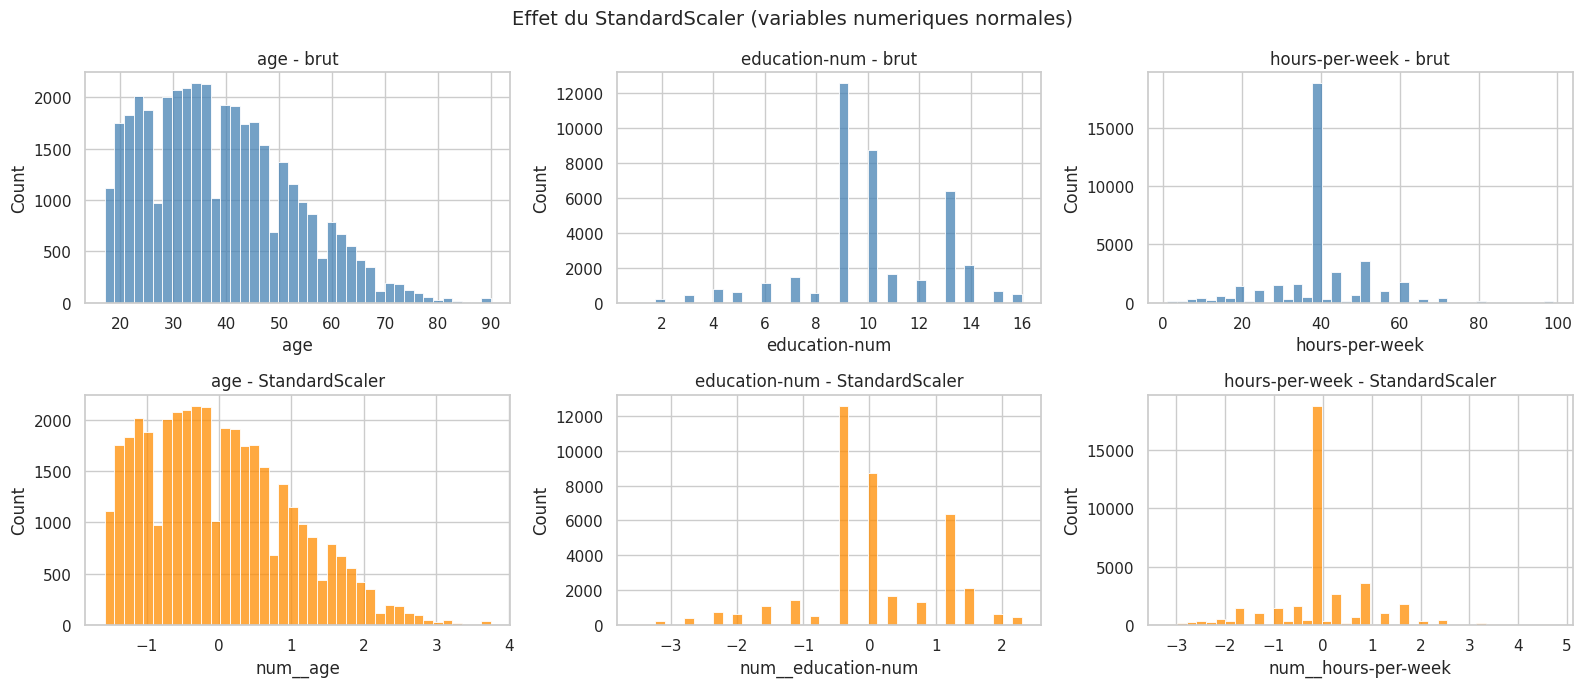

      num__age  num__education-num  num__hours-per-week
mean       0.0                 0.0                 -0.0
std        1.0                 1.0                  1.0


In [8]:
fig, axes = plt.subplots(2, len(NORMAL_NUMERICAL_FEATURES), figsize=(16, 7))
for j, col in enumerate(NORMAL_NUMERICAL_FEATURES):
    sns.histplot(X_train[col], ax=axes[0, j], bins=40, color="steelblue")
    axes[0, j].set_title(f"{col} - brut")
    sns.histplot(X_train_t[f"num__{col}"], ax=axes[1, j], bins=40, color="darkorange")
    axes[1, j].set_title(f"{col} - StandardScaler")
fig.suptitle("Effet du StandardScaler (variables numeriques normales)", fontsize=14)
fig.tight_layout()
plt.show()

stats = X_train_t[[f"num__{c}" for c in NORMAL_NUMERICAL_FEATURES]].agg(["mean", "std"]).round(3)
print(stats.to_string())


### 4.3 Transformation `log1p` des variables asymétriques

`capital-gain` et `capital-loss` sont extrêmement asymétriques (la majorité des
valeurs valent 0, quelques très grosses valeurs). On applique `log1p` pour
compresser la queue de distribution, puis un `RobustScaler` (robuste aux
outliers) au lieu du `StandardScaler`.

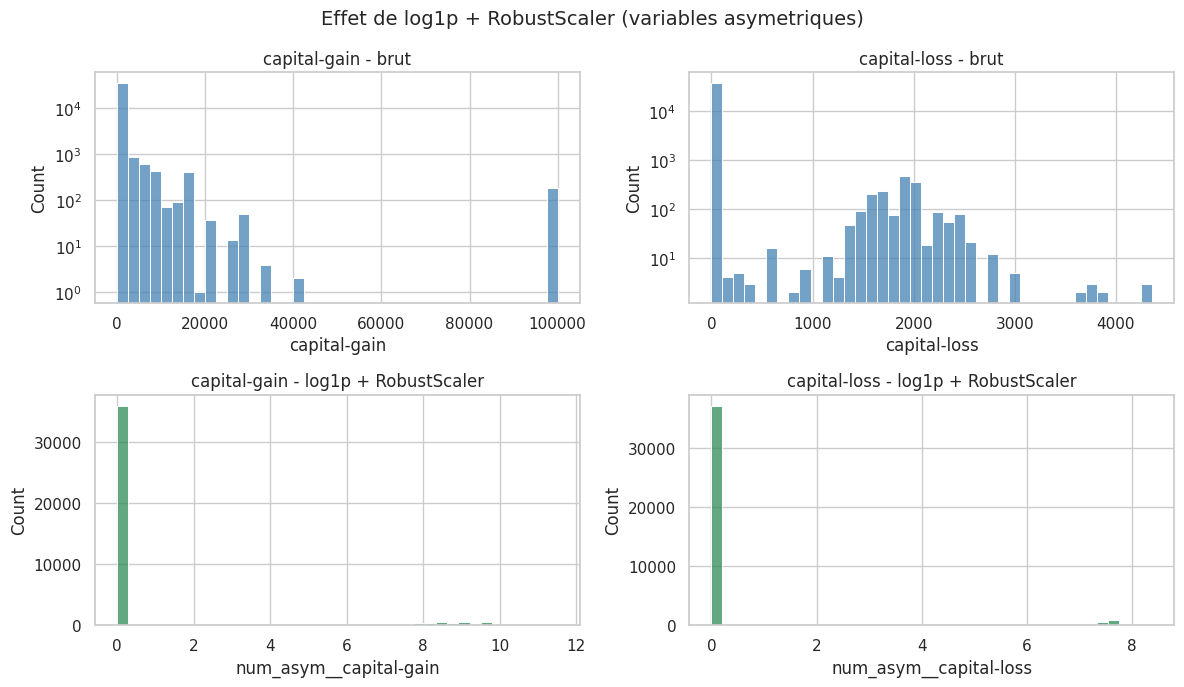

In [9]:
fig, axes = plt.subplots(2, len(ASYM_NUMERICAL_ACTIVE), figsize=(12, 7))
for j, col in enumerate(ASYM_NUMERICAL_ACTIVE):
    sns.histplot(X_train[col], ax=axes[0, j], bins=40, color="steelblue")
    axes[0, j].set_title(f"{col} - brut")
    axes[0, j].set_yscale("log")
    sns.histplot(X_train_t[f"num_asym__{col}"], ax=axes[1, j], bins=40, color="seagreen")
    axes[1, j].set_title(f"{col} - log1p + RobustScaler")
fig.suptitle("Effet de log1p + RobustScaler (variables asymetriques)", fontsize=14)
fig.tight_layout()
plt.show()


### 4.4 Encodage one-hot des catégorielles

Chaque variable catégorielle de faible cardinalité est éclatée en une colonne
binaire par modalité (`min_frequency=10` regroupe les modalités rares dans une
catégorie *infrequent*).

In [10]:
onehot_cols = [c for c in feat_names if c.startswith("cat__")]
print(f"{len(ONEHOT_CATEGORICAL_FEATURES)} variables one-hot  ->  {len(onehot_cols)} colonnes\n")
for base in ONEHOT_CATEGORICAL_FEATURES:
    n = sum(c.startswith(f"cat__{base}_") for c in feat_names)
    print(f"  {base:<16} -> {n:>3} modalites")


5 variables one-hot  ->  28 colonnes

  workclass        ->   8 modalites
  marital-status   ->   7 modalites
  relationship     ->   6 modalites
  race             ->   5 modalites
  sex              ->   2 modalites


### 4.5 Target encoding des variables à forte cardinalité

`occupation` et `native-country` ont trop de modalités pour le one-hot. Le
`TargetEncoder` remplace chaque modalité par une estimation (régularisée) du
taux de la classe positive. La valeur encodée **suit donc le taux réel de
`>50K`** par modalité.

In [11]:
high_cols = [c for c in feat_names if c.startswith("cat_high_card__")]
print("Colonnes target-encodees :", high_cols, "\n")

occ = pd.DataFrame({
    "occupation": X_train["occupation"].values,
    "valeur_encodee": X_train_t["cat_high_card__occupation"].values,
    "y": y_train_enc,
})
summary = (
    occ.groupby("occupation")
    .agg(taux_reel_50K=("y", "mean"), valeur_encodee=("valeur_encodee", "mean"), n=("y", "size"))
    .sort_values("taux_reel_50K", ascending=False)
    .round(3)
)
summary


Colonnes target-encodees : ['cat_high_card__occupation', 'cat_high_card__native-country'] 



,taux_reel_50K,valeur_encodee,n
occupation,,,
Exec-managerial,0.473,0.472,4893
Prof-specialty,0.456,0.343,4915
Armed-Forces,0.357,0.329,14
Protective-serv,0.319,0.319,806
Tech-support,0.286,0.286,1124
Sales,0.272,0.272,4413
Craft-repair,0.226,0.226,4872
Transport-moving,0.209,0.209,1908
Adm-clerical,0.137,0.137,4466


## 5. Comparaison des stratégies d'encodage : `onehot` vs `ordinal`

La pipeline accepte un paramètre `encoding`. Le one-hot convient aux modèles
linéaires mais gonfle la dimensionnalité ; l'ordinal est compact et adapté aux
modèles à base d'arbres.

In [12]:
results = {}
for enc in ["onehot", "ordinal"]:
    p = PreprocessingPipeline(encoding=enc, scaling=True)
    p.fit_transform_target(y_train)
    pre_e = p.build()
    Xt = pre_e.fit_transform(X_train, y_train_enc)
    results[enc] = Xt.shape[1]

pd.DataFrame.from_dict(results, orient="index", columns=["n_colonnes_sortie"])


,n_colonnes_sortie
onehot,35
ordinal,12


## 6. Transformation cohérente du jeu de test

Le test est transformé avec `transform` (et **non** `fit_transform`) : on
réutilise les statistiques apprises sur le train (médianes, moyennes/écarts,
modalités, encodage cible). Aucune fuite, et le test produit exactement les
mêmes colonnes.

In [13]:
X_test_t = pre.transform(X_test)

print(f"Train transforme : {X_train_t.shape}")
print(f"Test  transforme : {X_test_t.shape}")
print("Memes colonnes           :", X_test_t.shape[1] == X_train_t.shape[1])
print("NaN dans le test         :", int(np.isnan(X_test_t).sum()))


Train transforme : (39073, 35)
Test  transforme : (9769, 35)
Memes colonnes           : True
NaN dans le test         : 0


## 7. Récapitulatif

- **`?` → NaN → imputation** : plus aucune valeur manquante en sortie.
- **Numériques normales** : recentrées/réduites (`StandardScaler`).
- **`capital-gain` / `capital-loss`** : `log1p` + `RobustScaler` pour dompter
  l'asymétrie et les outliers.
- **Catégorielles faible cardinalité** : one-hot (dimensionnalité ↑).
- **`occupation` / `native-country`** : target encoding (1 colonne, suit le taux
  de `>50K`).
- **`education` / `fnlwgt`** : ignorées (`remainder="drop"`).
- La pipeline est **ajustée sur le train**, appliquée à l'identique au test →
  pas de data leakage.

Cette matrice transformée est l'entrée directe des modèles dans le notebook de
modélisation.
